In [2]:
import requests, time, os, subprocess
art = requests.get("https://api.figshare.com/v2/articles/23541312").json()
for f in art["files"]:
    print(f["id"], f["name"], round(f["size"]/1e9,2), "GB", f["download_url"])

url = art["files"][0]["download_url"]   # change index if the list shows several files
out = "/content/UMD.zip"
for i in range(10):
    subprocess.run(["wget", "-q", "-c", "-L", "-O", out, url])
    sz = os.path.getsize(out) if os.path.exists(out) else 0
    print("attempt", i+1, "size GB:", round(sz/1e9, 2))
    if sz > 1e8:
        break
    time.sleep(30)

44111183 UMD.zip 4.76 GB https://ndownloader.figshare.com/files/44111183
attempt 1 size GB: 4.76


In [3]:
!unzip -q /content/UMD.zip -d /content/UMD
!find /content/UMD -maxdepth 3 | head -40
!find /content/UMD -type f | sed 's/.*\.//' | sort | uniq -c
!du -sh /content/UMD

/content/UMD
/content/UMD/UMD
/content/UMD/UMD/UMD_221129_201
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_23.dcm
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_10.dcm
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_01.dcm
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_18.dcm
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_13.dcm
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_04.dcm
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_15.dcm
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_24.dcm
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_07.dcm
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_seg.nii.gz
/content/UMD/UMD/UMD_221129_201/.DS_Store
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_22.dcm
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_05.dcm
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_20.dcm
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_03.dcm
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_14.dcm
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_t2.nii.gz
/content/UMD/UMD/UMD_2211

In [4]:
!ls /content/UMD | head
!find /content/UMD -maxdepth 2 | head -30
!echo ---FILES---
!find /content/UMD -type f | head -20
!echo ---COUNT---
!find /content/UMD -type f | wc -l

__MACOSX
UMD
/content/UMD
/content/UMD/UMD
/content/UMD/UMD/UMD_221129_201
/content/UMD/UMD/UMD_221129_159
/content/UMD/UMD/UMD_221129_045
/content/UMD/UMD/UMD_221129_292
/content/UMD/UMD/UMD_221129_243
/content/UMD/UMD/UMD_221129_157
/content/UMD/UMD/UMD_221129_093
/content/UMD/UMD/UMD_221129_166
/content/UMD/UMD/UMD_221129_229
/content/UMD/UMD/UMD_221129_237
/content/UMD/UMD/UMD_221129_154
/content/UMD/UMD/UMD_221129_035
/content/UMD/UMD/UMD_221129_175
/content/UMD/UMD/UMD_221129_149
/content/UMD/UMD/UMD_221129_241
/content/UMD/UMD/UMD_221129_283
/content/UMD/UMD/UMD_221129_141
/content/UMD/UMD/UMD_221129_004
/content/UMD/UMD/UMD_221129_225
/content/UMD/UMD/UMD_221129_103
/content/UMD/UMD/UMD_221129_092
/content/UMD/UMD/UMD_221129_091
/content/UMD/UMD/UMD_221129_169
/content/UMD/UMD/UMD_221129_253
/content/UMD/UMD/UMD_221129_130
/content/UMD/UMD/UMD_221129_044
/content/UMD/UMD/UMD_221129_033
/content/UMD/UMD/UMD_221129_113
---FILES---
/content/UMD/UMD/UMD_221129_201/UMD_221129_201_23

In [5]:
import glob, os, numpy as np, pandas as pd, nibabel as nib
from scipy import ndimage as ndi

root = "/content/UMD/UMD"
cases = sorted(d for d in glob.glob(f"{root}/UMD_*") if os.path.isdir(d))
print("cases:", len(cases))

rows, labelset = [], {}
st3 = np.ones((3,3,3), dtype=int)
for d in cases:
    cid = os.path.basename(d)
    r = {"case": cid}
    try:
        t2p = glob.glob(f"{d}/*_t2.nii.gz"); sgp = glob.glob(f"{d}/*_seg.nii.gz")
        r["n_dcm"] = len(glob.glob(f"{d}/*.dcm"))
        if not t2p or not sgp:
            r["error"] = f"missing t2={len(t2p)} seg={len(sgp)}"; rows.append(r); continue
        t2 = nib.load(t2p[0]); sg = nib.load(sgp[0])
        a = np.asarray(sg.dataobj).astype(int)
        r["shape_t2"] = str(t2.shape); r["shape_seg"] = str(sg.shape)
        r["shape_match"] = t2.shape == sg.shape
        sp = sg.header.get_zooms()[:3]; r["spacing"] = tuple(round(float(s),2) for s in sp)
        r["axcodes"] = "".join(nib.aff2axcodes(sg.affine))
        vals, cnts = np.unique(a, return_counts=True)
        r["labels"] = dict(zip(vals.tolist(), cnts.tolist()))
        for v, c in zip(vals.tolist(), cnts.tolist()):
            labelset[v] = labelset.get(v, 0) + 1
        vox_mm3 = float(np.prod(sp))
        # components per label (3D, 26-connectivity)
        for v in vals.tolist():
            if v == 0: continue
            lab, n = ndi.label(a == v, structure=st3)
            sizes = np.bincount(lab.ravel())[1:]
            r[f"n_comp_{v}"] = int(n)
            r[f"min_comp_vox_{v}"] = int(sizes.min()) if n else 0
            r[f"max_comp_vox_{v}"] = int(sizes.max()) if n else 0
            r[f"vol_mm3_{v}"] = round(float(sizes.sum()) * vox_mm3, 1)
    except Exception as e:
        r["error"] = repr(e)
    rows.append(r)

df = pd.DataFrame(rows)
df.to_csv("/content/umd_audit.csv", index=False)
print("\nLabel values present (value: #cases):", dict(sorted(labelset.items())))
print("errors:", df["error"].notna().sum() if "error" in df else 0)
print("shape_match all:", df["shape_match"].all())
print("\nshapes:\n", df["shape_seg"].value_counts().head(8))
print("\nspacing:\n", df["spacing"].value_counts().head(8))
print("\naxcodes:\n", df["axcodes"].value_counts())
print("\nSlices (dcm) per case:", df["n_dcm"].describe()[["min","50%","max"]].to_dict())
for c in [c for c in df.columns if c.startswith("n_comp_")]:
    print(f"\n{c}:", df[c].describe()[["min","50%","max"]].to_dict(),
          " cases with >1:", int((df[c] > 1).sum()))

cases: 300

Label values present (value: #cases): {0: 266, 1: 266, 2: 266, 3: 266, 4: 127}
errors: 34
shape_match all: True

shapes:
 shape_seg
(560, 560, 20)    78
(512, 512, 24)    65
(672, 672, 20)    39
(800, 800, 24)    21
(528, 528, 25)    19
(560, 560, 24)    10
(640, 640, 20)     4
(512, 512, 25)     4
Name: count, dtype: int64

spacing:
 spacing
(0.5, 0.5, 6.6)      76
(0.48, 0.48, 4.4)    56
(0.45, 0.45, 6.6)    41
(0.75, 0.75, 5.5)    20
(0.31, 0.31, 4.4)    14
(0.48, 0.48, 5.5)    11
(0.49, 0.49, 6.6)     5
(0.31, 0.31, 5.5)     5
Name: count, dtype: int64

axcodes:
 axcodes
PIR    266
Name: count, dtype: int64

Slices (dcm) per case: {'min': 20.0, '50%': 24.0, 'max': 32.0}

n_comp_1: {'min': 1.0, '50%': 1.0, 'max': 13.0}  cases with >1: 50

n_comp_2: {'min': 1.0, '50%': 1.0, 'max': 6.0}  cases with >1: 97

n_comp_3: {'min': 1.0, '50%': 2.0, 'max': 17.0}  cases with >1: 176

n_comp_4: {'min': 1.0, '50%': 2.0, 'max': 14.0}  cases with >1: 84


               case  n_dcm                                                                                                 error
36   UMD_221129_037     30  ImageFileError('File /content/UMD/UMD/UMD_221129_037/UMD_2221129_037_seg.nii.gz is not a gzip file')
44   UMD_221129_045     30                                                                                    missing t2=1 seg=0
45   UMD_221129_046     24                                                                                    missing t2=1 seg=0
49   UMD_221129_050     30                                                                                    missing t2=1 seg=0
53   UMD_221129_054     24                                                                                    missing t2=1 seg=0
54   UMD_221129_055     30                                                                                    missing t2=1 seg=0
58   UMD_221129_059     30                                                                       

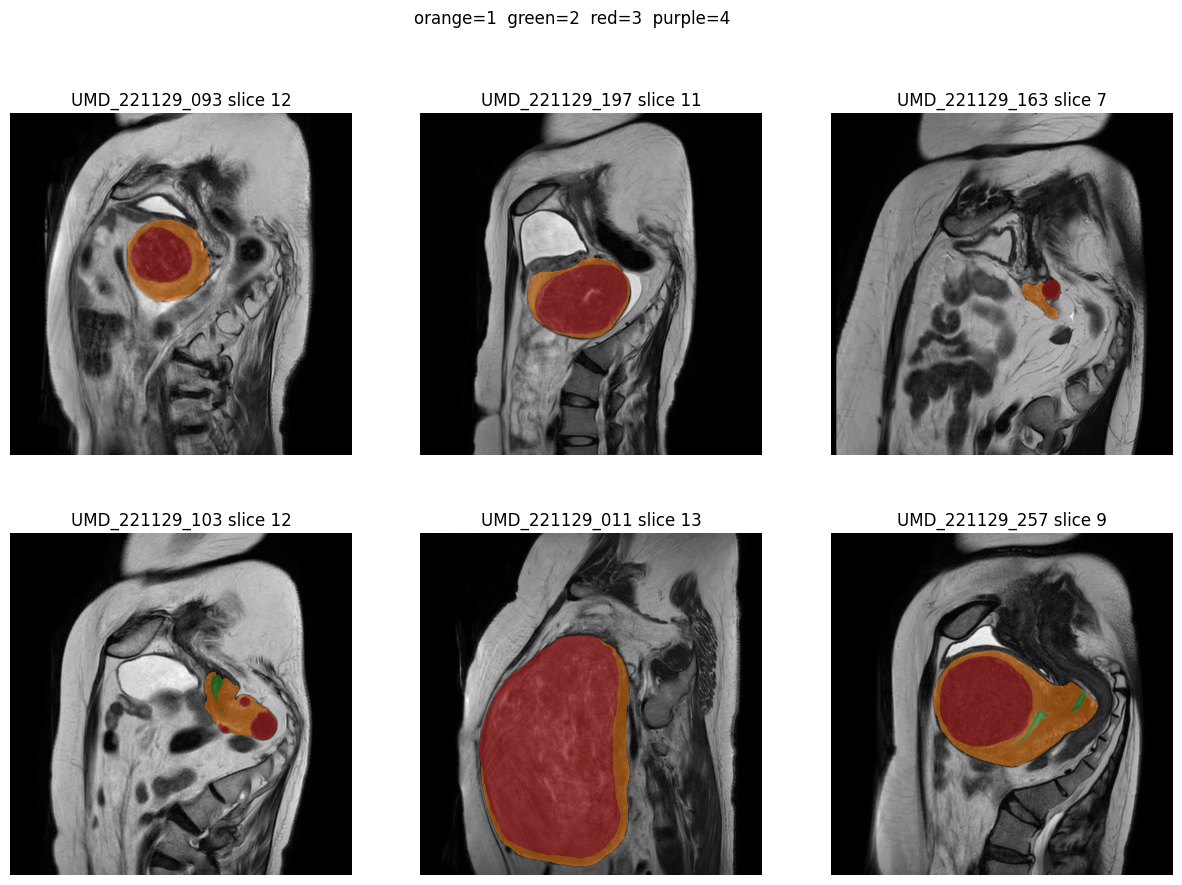


myoma components: 814 in 266 cases
eq_diam_mm
(0, 10]       357
(10, 20]      229
(20, 40]      120
(40, 1000]    108
Name: count, dtype: int64
components spanning only 1 slice: 347


In [6]:
import matplotlib.pyplot as plt
print(df[df["error"].notna()][["case","n_dcm","error"]].to_string())

vcols = [c for c in df.columns if c.startswith("vol_mm3_")]
print("\nmedian volume mm3 per label:\n", df[vcols].median())

ok = df[df["error"].isna()]["case"].tolist()
rng = np.random.default_rng(0)
fig, axs = plt.subplots(2, 3, figsize=(15, 10))
for ax, cid in zip(axs.ravel(), rng.choice(ok, 6, replace=False)):
    d = f"{root}/{cid}"
    t2 = np.asarray(nib.load(glob.glob(f"{d}/*_t2.nii.gz")[0]).dataobj)
    s = np.asarray(nib.load(glob.glob(f"{d}/*_seg.nii.gz")[0]).dataobj).astype(int)
    k = int(np.argmax((s == 3).sum(axis=(0, 1))))
    ax.imshow(np.rot90(t2[:, :, k]), cmap="gray")
    ax.imshow(np.rot90(np.ma.masked_where(s[:, :, k] == 0, s[:, :, k])),
              cmap="tab10", alpha=0.5, vmin=0, vmax=9)
    ax.set_title(f"{cid} slice {k}"); ax.axis("off")
plt.suptitle("orange=1  green=2  red=3  purple=4"); plt.show()

recs = []
for cid in ok:
    d = f"{root}/{cid}"
    sg = nib.load(glob.glob(f"{d}/*_seg.nii.gz")[0])
    a = np.asarray(sg.dataobj).astype(int)
    vox = float(np.prod(sg.header.get_zooms()[:3]))
    lab, n = ndi.label(a == 3, structure=st3)
    for i in range(1, n + 1):
        m = lab == i
        v = m.sum() * vox
        recs.append({"case": cid, "vol_mm3": v,
                     "eq_diam_mm": (6 * v / np.pi) ** (1 / 3),
                     "z_slices": int(m.any(axis=(0, 1)).sum())})
L = pd.DataFrame(recs)
L.to_csv("/content/umd_myoma_components.csv", index=False)
print("\nmyoma components:", len(L), "in", L["case"].nunique(), "cases")
print(pd.cut(L["eq_diam_mm"], [0, 10, 20, 40, 1000]).value_counts().sort_index())
print("components spanning only 1 slice:", int((L["z_slices"] == 1).sum()))

In [7]:
L = pd.read_csv("/content/umd_myoma_components.csv")
print(pd.cut(L["eq_diam_mm"], [0,10,20,40,1000]).value_counts().sort_index())
print("single-slice:", int((L["z_slices"]==1).sum()), "| under 1 cm3:", int((L["vol_mm3"]<1000).sum()))
bad = df[df["error"].notna()]["case"].tolist()
for c in bad[:3]:
    print(c, [os.path.basename(f) for f in glob.glob(f"{root}/{c}/*") if not f.endswith(".dcm")])

eq_diam_mm
(0, 10]       357
(10, 20]      229
(20, 40]      120
(40, 1000]    108
Name: count, dtype: int64
single-slice: 347 | under 1 cm3: 446
UMD_221129_037 ['UMD_221129_037_t2.nii.gz', 'UMD_2221129_037_seg.nii.gz']
UMD_221129_045 ['UMD_221129_045_t2.nii.gz', 'UMD_221129_045_seq.nii.gz']
UMD_221129_046 ['UMD_221129_046_seq.nii.gz', 'UMD_221129_046_t2.nii.gz']


In [8]:
!pip -q install nnunetv2
from google.colab import drive; drive.mount('/content/drive')
import os, glob, json, shutil, numpy as np, nibabel as nib
base="/content/nnUNet"
for p in ["raw","preprocessed","results"]: os.makedirs(f"{base}/{p}", exist_ok=True)
for k,p in [("nnUNet_raw","raw"),("nnUNet_preprocessed","preprocessed"),("nnUNet_results","results")]:
    os.environ[k]=f"{base}/{p}"
ds=f"{base}/raw/Dataset501_UMD"
os.makedirs(f"{ds}/imagesTr",exist_ok=True); os.makedirs(f"{ds}/labelsTr",exist_ok=True)
keep, skipped, mism = [], [], 0
for d in sorted(glob.glob(f"{root}/UMD_*")):
    cid=os.path.basename(d)
    t2p=glob.glob(f"{d}/*_t2.nii.gz"); sgp=glob.glob(f"{d}/*_seg.nii.gz")
    if not t2p or not sgp: skipped.append(cid); continue
    t2=nib.load(t2p[0]); sg=nib.load(sgp[0])
    if not np.allclose(t2.affine, sg.affine, atol=1e-3): mism+=1
    shutil.copy(t2p[0], f"{ds}/imagesTr/{cid}_0000.nii.gz")
    lab=np.asarray(sg.dataobj).round().astype(np.uint8)
    img=nib.Nifti1Image(lab, t2.affine); img.set_data_dtype(np.uint8)
    nib.save(img, f"{ds}/labelsTr/{cid}.nii.gz"); keep.append(cid)
json.dump({"channel_names":{"0":"T2"},
 "labels":{"background":0,"wall":1,"cavity":2,"myoma":3,"nabothian_cyst":4},
 "numTraining":len(keep),"file_ending":".nii.gz"}, open(f"{ds}/dataset.json","w"), indent=2)
print(len(keep),"kept |",len(skipped),"skipped | affine mismatches:",mism)
!mkdir -p /content/drive/MyDrive/myomaguard
!cp -r {ds} /content/drive/MyDrive/myomaguard/
!nnUNetv2_plan_and_preprocess -d 501 --verify_dataset_integrity -c 2d

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 291.1/291.1 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.8/106.8 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.6/53.6 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.4/28.4 MB 73.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 94.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 99.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.4/96.4 kB 9.7 MB/s eta 0:00:00
Mounted at /content/drive


ImageFileError: File /content/UMD/UMD/UMD_221129_037/UMD_2221129_037_seg.nii.gz is not a gzip file

In [9]:
import os, glob, json, shutil, numpy as np, nibabel as nib
base="/content/nnUNet"
for k,p in [("nnUNet_raw","raw"),("nnUNet_preprocessed","preprocessed"),("nnUNet_results","results")]:
    os.makedirs(f"{base}/{p}", exist_ok=True); os.environ[k]=f"{base}/{p}"
ds=f"{base}/raw/Dataset501_UMD"
shutil.rmtree(ds, ignore_errors=True)
os.makedirs(f"{ds}/imagesTr"); os.makedirs(f"{ds}/labelsTr")

def load_any(path):
    with open(path,"rb") as f: head=f.read(4)
    if head[:2]==b"\x1f\x8b": return nib.load(path)
    if head in (b"\x5c\x01\x00\x00", b"\x00\x00\x01\x5c"):   # plain NIfTI named .gz
        shutil.copy(path,"/tmp/_tmp.nii"); return nib.load("/tmp/_tmp.nii")
    raise ValueError("unknown format")

keep, no_seg, bad, mism = [], [], [], []
for d in sorted(glob.glob(f"{root}/UMD_*")):
    cid=os.path.basename(d)
    t2p=glob.glob(f"{d}/*_t2.nii*")
    sgp=[f for f in glob.glob(f"{d}/*") if f.endswith((".nii",".nii.gz")) and "t2" not in os.path.basename(f).lower()]
    if not t2p or not sgp: no_seg.append(cid); continue
    try:
        t2=load_any(t2p[0]); t2data=np.asarray(t2.dataobj).astype(np.float32); t2aff=t2.affine
        sg=load_any(sgp[0]); lab=np.asarray(sg.dataobj).round().astype(np.uint8); saff=sg.affine
        if lab.shape!=t2data.shape: bad.append((cid,"shape")); continue
        if not np.allclose(t2aff,saff,atol=1e-3): mism.append(cid)
        nib.save(nib.Nifti1Image(t2data,t2aff), f"{ds}/imagesTr/{cid}_0000.nii.gz")
        nib.save(nib.Nifti1Image(lab,t2aff), f"{ds}/labelsTr/{cid}.nii.gz")
        keep.append(cid)
    except Exception as e:
        bad.append((cid,repr(e)[:80]))
json.dump({"channel_names":{"0":"T2"},
 "labels":{"background":0,"wall":1,"cavity":2,"myoma":3,"nabothian_cyst":4},
 "numTraining":len(keep),"file_ending":".nii.gz"}, open(f"{ds}/dataset.json","w"), indent=2)
print(len(keep),"kept | no seg:",no_seg,"| bad:",bad,"| affine mismatches:",len(mism),mism[:10])

300 kept | no seg: [] | bad: [] | affine mismatches: 33 ['UMD_221129_045', 'UMD_221129_046', 'UMD_221129_050', 'UMD_221129_054', 'UMD_221129_055', 'UMD_221129_059', 'UMD_221129_060', 'UMD_221129_061', 'UMD_221129_062', 'UMD_221129_063']


              case  max_affine_diff t2_axes seg_axes                   seg_file
0   UMD_221129_045          160.056     PIR      RAS  UMD_221129_045_seq.nii.gz
1   UMD_221129_046          176.830     PIR      RAS  UMD_221129_046_seq.nii.gz
2   UMD_221129_050          111.751     PIR      RAS  UMD_221129_050_seq.nii.gz
3   UMD_221129_054          107.833     PIR      RAS  UMD_221129_054_seq.nii.gz
4   UMD_221129_055          216.869     PIR      RAS  UMD_221129_055_seq.nii.gz
5   UMD_221129_059          171.323     PIR      RAS  UMD_221129_059_seq.nii.gz
6   UMD_221129_060          168.172     PIR      RAS  UMD_221129_060_seq.nii.gz
7   UMD_221129_061          172.815     PIR      RAS  UMD_221129_061_seq.nii.gz
8   UMD_221129_062          142.852     PIR      RAS  UMD_221129_062_seq.nii.gz
9   UMD_221129_063          249.183     PIR      RAS  UMD_221129_063_seq.nii.gz
10  UMD_221129_064          255.235     PIR      RAS  UMD_221129_064_seq.nii.gz
11  UMD_221129_070          101.015     

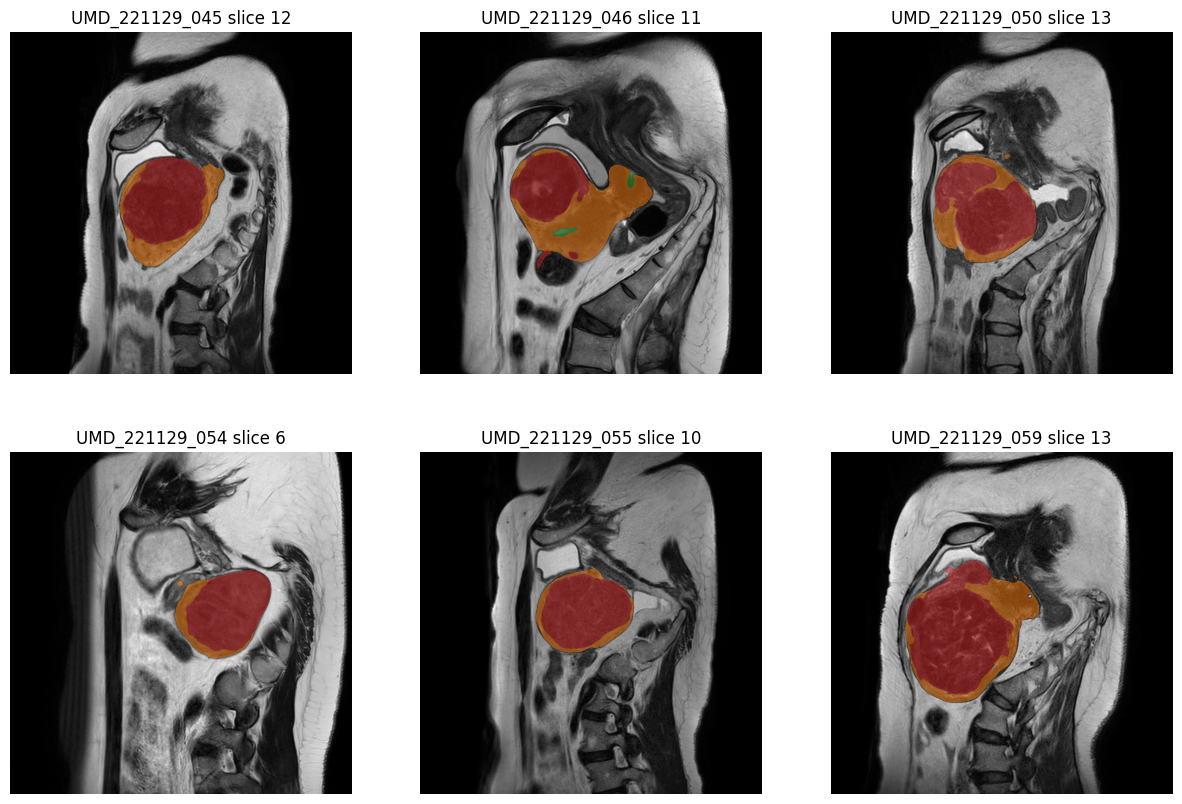

UMD_221129_200 ['UMD_221129_200_seq.nii.gz', 'UMD_221129_200_t2.nii.gz']
UMD_221129_222 ['UMD_221129_222_seq.nii.gz', 'UMD_221129_222_t2.nii.gz']
UMD_221129_241 ['UMD_221129_241_t2.nii.gz', 'UMD_221129_241_seq.nii.gz']
UMD_221129_249 ['UMD_221129_249_seq.nii.gz', 'UMD_221129_249_t2.nii.gz']
label values across all: [0, 1, 2, 3, 4]


In [10]:
import matplotlib.pyplot as plt
mm = mism
diffs=[]
for cid in mm:
    d=f"{root}/{cid}"
    t2=load_any(glob.glob(f"{d}/*_t2.nii*")[0])
    sgf=[f for f in glob.glob(f"{d}/*") if f.endswith((".nii",".nii.gz")) and "t2" not in os.path.basename(f).lower()][0]
    sg=load_any(sgf)
    diffs.append((cid, round(float(np.abs(t2.affine-sg.affine).max()),3),
                  "".join(nib.aff2axcodes(t2.affine)), "".join(nib.aff2axcodes(sg.affine)), os.path.basename(sgf)))
print(pd.DataFrame(diffs, columns=["case","max_affine_diff","t2_axes","seg_axes","seg_file"]).to_string())

fig, axs = plt.subplots(2, 3, figsize=(15, 10))
for ax, cid in zip(axs.ravel(), mm[:6]):
    t2=np.asarray(nib.load(f"{ds}/imagesTr/{cid}_0000.nii.gz").dataobj)
    s=np.asarray(nib.load(f"{ds}/labelsTr/{cid}.nii.gz").dataobj)
    k=int(np.argmax((s==3).sum(axis=(0,1))))
    ax.imshow(np.rot90(t2[:,:,k]),cmap="gray")
    ax.imshow(np.rot90(np.ma.masked_where(s[:,:,k]==0,s[:,:,k])),cmap="tab10",alpha=0.5,vmin=0,vmax=9)
    ax.set_title(f"{cid} slice {k}"); ax.axis("off")
plt.show()

# the 4 cases that earlier showed no seg: what file did we pick?
for cid in ["UMD_221129_200","UMD_221129_222","UMD_221129_241","UMD_221129_249"]:
    print(cid, [os.path.basename(f) for f in glob.glob(f"{root}/{cid}/*") if not f.endswith(".dcm")])
print("label values across all:", sorted({int(v) for c in keep for v in np.unique(np.asarray(nib.load(f"{ds}/labelsTr/{c}.nii.gz").dataobj))}))

In [11]:
!mkdir -p /content/drive/MyDrive/firma
!cp -r /content/nnUNet/raw/Dataset501_UMD /content/drive/MyDrive/firma/
!nnUNetv2_plan_and_preprocess -d 501 --verify_dataset_integrity -c 2d

Fingerprint extraction...
Dataset501_UMD
Using <class 'nnunetv2.imageio.simpleitk_reader_writer.SimpleITKIO'> as reader/writer

####################
verify_dataset_integrity Done. 
If you didn't see any error messages then your dataset is most likely OK!
####################

Using <class 'nnunetv2.imageio.simpleitk_reader_writer.SimpleITKIO'> as reader/writer
Extracting dataset fingerprint: 100% 300/300 [02:31<00:00,  1.98it/s]
Experiment planning...

############################
INFO: You are using the old nnU-Net default planner. We have updated our recommendations. Please consider using those instead! Read more here: https://github.com/MIC-DKFZ/nnUNet/blob/master/documentation/resenc_presets.md
############################

Attempting to find 3d_lowres config. 
Current spacing: [4.4000001  0.49838708 0.49838708]. 
Current patch size: (np.int64(16), np.int64(320), np.int64(320)). 
Current median shape: [ 30.         557.2815534  501.94174757]
Attempting to find 3d_lowres config. 
Cu

In [12]:
!nvidia-smi | head -15
import os
os.environ["nnUNet_raw"]="/content/nnUNet/raw"
os.environ["nnUNet_preprocessed"]="/content/nnUNet/preprocessed"
os.environ["nnUNet_results"]="/content/drive/MyDrive/myomaguard/results"
os.makedirs(os.environ["nnUNet_results"], exist_ok=True)
!nnUNetv2_train 501 2d 0 -tr nnUNetTrainer_50epochs --npz

Wed Oct 21 18:06:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----